# From Logistic Regression to a Neural Network - Solution

**Business problem:** identify spam without flagging too many legitimate emails for review. One observation is one email: **0 = ham, 1 = spam**.

In this notebook, we will:
1. Prepare identical, training-scaled features for both models.
2. Reproduce logistic regression's sigmoid output and train a small MLP.
3. Select a hidden-layer size and decision thresholds using validation data.
4. Interpret historical test evidence, business costs and limitations.

This is the completed companion to the [exercise](logistic_regression_to_neural_network_exercise.ipynb). Read the [concepts](logistic_regression_to_neural_network_concept.ipynb) first. Run from top to bottom; the numbered steps, variables and settings match the exercise. Expand each answer after interpreting the output yourself.

This accompanies **SW07 Lecture 1** and assumes logistic regression, train/validation/test splits and basic Python. One worked step fits the lecture's 10-minute demonstration slot; the full practical belongs in a separate session. The core needs only the repository's base environment and local data. XGBoost, embeddings, persistence and a deeper network are optional extensions and are not required here.

## Libraries and settings

Import the libraries, set the random seed and locate the local email data. The same settings and prepared features are used throughout the main comparison.

In [1]:
from pathlib import Path
import importlib.metadata
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 7
LABEL_MEANINGS = {0: 'ham', 1: 'spam'}
np.random.seed(SEED)
search_roots = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((root for root in search_roots
                  if (root / '00_Data' / 'email_spam.csv').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Open this notebook from inside python_machine_learning_basics; 00_Data/email_spam.csv must be present.')
DATA_DIR = REPO_ROOT / '00_Data'
NOTEBOOK_DIR = REPO_ROOT / '08_Neural_Networks' / 'HS2026'
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))
from enron_features import EmailFeatures, FEATURE_NAMES

versions = {package: importlib.metadata.version(package)
            for package in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']}
print('Data directory:', DATA_DIR)
print('Documented labels:', LABEL_MEANINGS)
display(pd.Series(versions, name='Installed version'))

Data directory: /Users/iaracena/VisualStudioProjects/ZHAW/python_machine_learning_basics/00_Data
Documented labels: {0: 'ham', 1: 'spam'}


numpy           1.26.4
pandas           2.2.3
scikit-learn     1.6.1
matplotlib       3.9.4
Name: Installed version, dtype: object

## 1. Import the prepared email data

The supplied code reads the local CSV explicitly and keeps its stored **18,000 training, 6,000 validation and 6,000 test rows**. One observation is one email; labels are 0 = ham and 1 = spam. No raw subjects or bodies are included.

Preparation removed empty and normalized exact-duplicate messages and quarantined conflicting labels before sampling with seed 7. Related campaigns and near-duplicates may remain across splits. Do not resplit this reference data.

**Question:** Which four columns must not become predictors? Why do we retain the stored split membership?

<details>
<summary>Answer and self-check</summary>

**Answer:** Exclude `label`, `split`, `source_row` and `message_key` from model inputs. The label is the target; the others identify partitions or provenance, not email content. Keeping the stored splits makes comparisons reproducible and prevents moving already evaluated messages into development data. We compare the models on identical rows and features.

**Basic, 2 points:** identify the excluded metadata/target columns (1); explain fixed evaluation boundaries (1). **Common mistake:** treating a numeric source-row identifier as an informative feature.

</details>

In [2]:
email_data_path = DATA_DIR / 'email_spam.csv'
prepared_emails = pd.read_csv(email_data_path)

train = prepared_emails.loc[prepared_emails['split'].eq('train')].copy()
validation = prepared_emails.loc[prepared_emails['split'].eq('validation')].copy()
test = prepared_emails.loc[prepared_emails['split'].eq('test')].copy()

print('Loaded:', email_data_path.resolve())
print(f'Ready: {len(train):,} training, {len(validation):,} validation and {len(test):,} test emails.')

Loaded: /Users/iaracena/VisualStudioProjects/ZHAW/python_machine_learning_basics/00_Data/email_spam.csv
Ready: 18,000 training, 6,000 validation and 6,000 test emails.


In [3]:
display(pd.DataFrame({
    'Split': ['Training', 'Validation', 'Test'],
    'Emails': [len(train), len(validation), len(test)],
    'Purpose': ['Fit models', 'Choose settings and thresholds', 'Evaluate fixed choices'],
}))

,Split,Emails,Purpose
0,Training,18000,Fit models
1,Validation,6000,Choose settings and thresholds
2,Test,6000,Evaluate fixed choices


## 2. Select and scale shared inputs

Both models receive the same 16 count and ratio features: message size, uppercase/digit ratios, punctuation, symbols, links, subject length and six promotional-word counts. The supplied helper selects those features in a fixed order; it can also compute them from new subject/body inputs. These inputs describe patterns, not meaning.

**Coding task:** in the preprocessing cell, obtain `X_train` by fitting and transforming `train_messages` with `preprocessing`, passing `y_train`. Validation and test transformations are supplied and must reuse that fitted pipeline. Preparation and histogram loops are provided.

**Question:** Why must the scaler see training data only? Why must we not fit a separate scaler on validation or test data?

<details>
<summary>Answer and self-check</summary>

**Answer:** `fit_transform` learns the training feature means and scales and applies them to training rows. `transform` then applies that same definition to validation and test rows. Fitting on all rows leaks evaluation information into model development; separate scalers would put each split in a different coordinate system. The identical fitted preprocessing is shared by logistic regression and the MLP.

**Basic, 2 points:** training-only fitting (1); reuse the same transformation for evaluation (1). **Common mistake:** calling `fit_transform` separately on each partition.

</details>

In [4]:
print('Select shared email features')
content_columns = list(FEATURE_NAMES)
train_messages = train[content_columns].copy()
validation_messages = validation[content_columns].copy()
test_messages = test[content_columns].copy()
y_train = train['label'].to_numpy()
y_validation = validation['label'].to_numpy()
y_test = test['label'].to_numpy()
feature_transformer = EmailFeatures()
raw_train_features = feature_transformer.fit_transform(train_messages)
display(raw_train_features.head())
display(raw_train_features.agg(['min', 'median', 'max']).T)
print('Inputs contain only:', train_messages.columns.tolist())

Select shared email features


,character_count,word_count,average_word_length,uppercase_letter_ratio,digit_ratio,exclamation_count,currency_symbol_count,url_count,email_address_count,subject_length,term_free_count,term_offer_count,term_winner_count,term_urgent_count,term_discount_count,term_unsubscribe_count
0,4080.0,753.0,4.053121,0.141559,0.100466,8.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,1.0
1,570.0,110.0,3.781818,0.016990,0.006969,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,496.0,86.0,4.604651,0.069948,0.020121,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,485.0,84.0,4.702381,0.058355,0.037037,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,422.0,71.0,4.535211,0.000000,0.014151,0.0,0.0,0.0,0.0,423.0,0.0,0.0,0.0,0.0,0.0,0.0


,min,median,max
character_count,3.000000,666.000000,1.192291e+06
word_count,1.000000,112.000000,1.606380e+05
average_word_length,1.242604,4.515754,5.742593e+01
uppercase_letter_ratio,0.000000,0.069536,1.000000e+00
digit_ratio,0.000000,0.019520,8.333333e-01
exclamation_count,0.000000,0.000000,3.950000e+02
currency_symbol_count,0.000000,0.000000,1.023900e+04
url_count,0.000000,0.000000,4.770000e+02
email_address_count,0.000000,0.000000,3.520000e+02
subject_length,0.000000,0.000000,9.336000e+03


Inputs contain only: ['character_count', 'word_count', 'average_word_length', 'uppercase_letter_ratio', 'digit_ratio', 'exclamation_count', 'currency_symbol_count', 'url_count', 'email_address_count', 'subject_length', 'term_free_count', 'term_offer_count', 'term_winner_count', 'term_urgent_count', 'term_discount_count', 'term_unsubscribe_count']


### Scale the input features

Fit the feature extractor and scaler on training emails only, then transform validation and test emails with the same fitted pipeline. The histograms describe selected training features; they do not guide changes using test data.

Fit shared preprocessing on training data only
Train / validation / test shapes: (18000, 16) (6000, 16) (6000, 16)


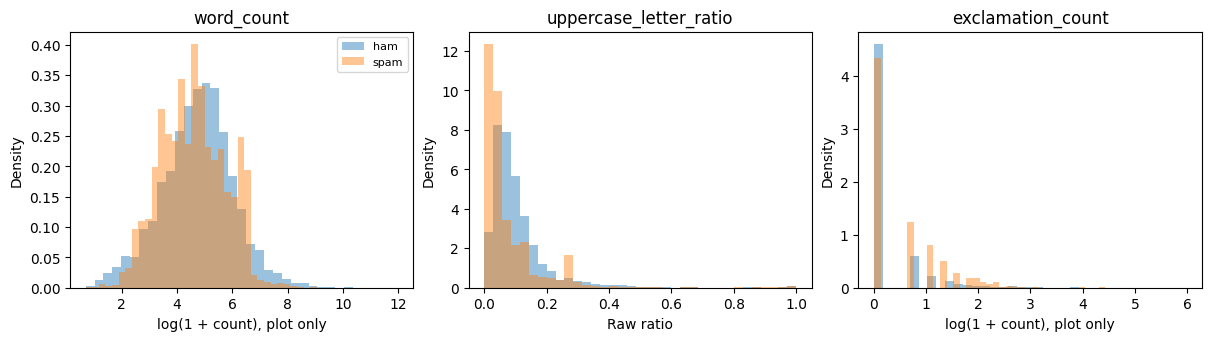

In [5]:
print('Fit shared preprocessing on training data only')
preprocessing = Pipeline([('features', EmailFeatures()), ('scale', StandardScaler())])
X_train = preprocessing.fit_transform(train_messages, y_train)
X_validation = preprocessing.transform(validation_messages)
X_test = preprocessing.transform(test_messages)
feature_names = preprocessing.named_steps['features'].get_feature_names_out()
print('Train / validation / test shapes:', X_train.shape, X_validation.shape, X_test.shape)
figure, axes = plt.subplots(1, 3, figsize=(12, 3.3), constrained_layout=True)
for axis, feature in zip(axes, ['word_count', 'uppercase_letter_ratio', 'exclamation_count']):
    for label, name in LABEL_MEANINGS.items():
        values = raw_train_features.loc[y_train == label, feature]
        if feature != 'uppercase_letter_ratio':
            values = np.log1p(values)
        axis.hist(values, bins=35, density=True, alpha=0.45, label=name)
    axis.set_title(feature)
    axis.set_xlabel('Raw ratio' if feature == 'uppercase_letter_ratio' else 'log(1 + count), plot only')
    axis.set_ylabel('Density')
axes[0].legend(fontsize=8)
plt.show()

## 3. Fit logistic regression and reproduce its output

**Coding task:** create `logistic` as a `LogisticRegression` estimator with `C=1.0`, `max_iter=1500` and `random_state=SEED`. Fitting, warning capture, a training-prior baseline, validation metrics and plots are supplied.

Logistic regression uses $z=\mathbf{w}^{T}\mathbf{x}+b$ followed by $p=1/(1+\exp(-z))$. Here $\mathbf{x}$ contains the scaled inputs, $\mathbf{w}$ the learned weights and $b$ the bias. The manual calculation below reproduces prediction, not training.

**Question:** How many trainable parameters are there? Does the manual sigmoid agree with `predict_proba`? Can a positive feature weight be interpreted as a causal effect?

<details>
<summary>Answer and self-check</summary>

**Answer:** There are 16 weights plus one bias, or **17 parameters**. The manual sigmoid and `predict_proba` agree up to floating-point precision. A positive coefficient increases predicted log-odds conditional on other model inputs; it does not show that changing that feature causes spam. Correlated counts make attribution unstable.

The prior baseline uses only the training spam proportion. Precision concerns flagged messages, recall concerns all actual spam, and AP summarizes ranking across thresholds. Neither a fitted probability nor a coefficient is itself an operational decision.

**Basic, 3 points:** parameter count (1); connect the score/sigmoid to the predicted probability (1); distinguish association from causation (1). **Common mistake:** counting only weights or interpreting coefficients as intervention effects.

</details>

In [6]:
print('Logistic regression as a single output neuron')
logistic = LogisticRegression(C=1.0, max_iter=1500, random_state=SEED)
with warnings.catch_warnings(record=True) as logistic_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    logistic.fit(X_train, y_train)
for warning in logistic_warnings:
    print(type(warning.message).__name__, str(warning.message))
weighted_sum = X_validation[:5] @ logistic.coef_[0] + logistic.intercept_[0]
manual_probability = np.exp(-np.logaddexp(0, -weighted_sum))
print('Parameters:', logistic.coef_.size + logistic.intercept_.size)
display(pd.DataFrame({'weighted_sum': weighted_sum, 'manual_sigmoid': manual_probability,
                      'predict_proba': logistic.predict_proba(X_validation[:5])[:, 1]}))

Logistic regression as a single output neuron
Parameters: 17


,weighted_sum,manual_sigmoid,predict_proba
0,-0.747741,0.321314,0.321314
1,0.364632,0.590161,0.590161
2,1.161086,0.761530,0.761530
3,-1.001909,0.268566,0.268566
4,-1.765360,0.146120,0.146120


Validation evaluation and feature weights


,precision,recall,f1,average_precision,flagged_fraction
Prior baseline,0.000000,0.000000,0.000000,0.296667,0.0000
Logistic regression,0.740916,0.263483,0.388728,0.599288,0.1055


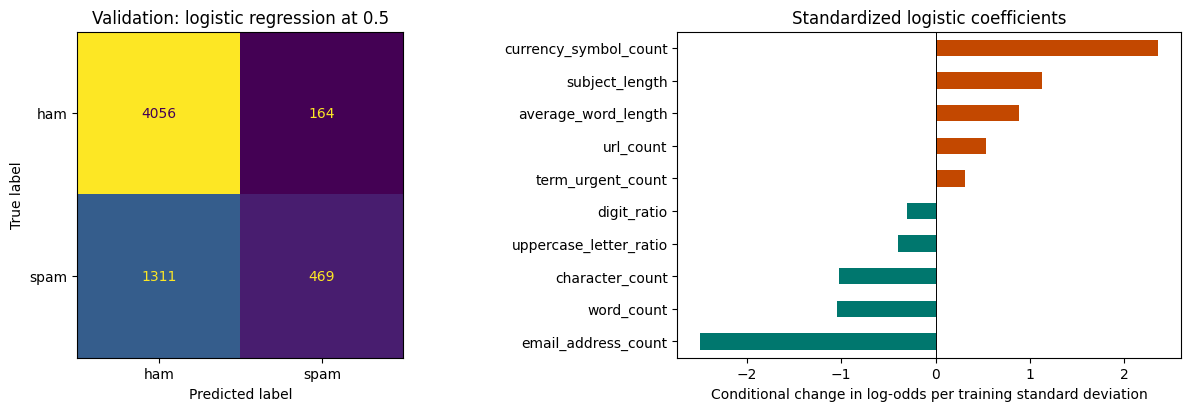

Coefficients describe model associations, not causal effects. Correlated counts make attribution unstable.


In [7]:
print('Validation evaluation and feature weights')


def metrics_at_threshold(targets, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {'precision': precision_score(targets, predictions, zero_division=0),
            'recall': recall_score(targets, predictions, zero_division=0),
            'f1': f1_score(targets, predictions, zero_division=0),
            'average_precision': average_precision_score(targets, probabilities),
            'flagged_fraction': float(predictions.mean())}


baseline = DummyClassifier(strategy='prior', random_state=SEED).fit(X_train, y_train)
validation_probabilities = {
    'Prior baseline': baseline.predict_proba(X_validation)[:, 1],
    'Logistic regression': logistic.predict_proba(X_validation)[:, 1],
}
display(pd.DataFrame({name: metrics_at_threshold(y_validation, probabilities)
                      for name, probabilities in validation_probabilities.items()}).T)
figure, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(y_validation, validation_probabilities['Logistic regression'] >= 0.5,
                                        display_labels=['ham', 'spam'], ax=axes[0], colorbar=False)
axes[0].set_title('Validation: logistic regression at 0.5')
coefficients = pd.Series(logistic.coef_[0], index=feature_names).sort_values()
coefficient_subset = pd.concat([coefficients.head(5), coefficients.tail(5)]).drop_duplicates().sort_values()
coefficient_subset.plot.barh(ax=axes[1], color=['#C34800' if value > 0 else '#00776E' for value in coefficient_subset])
axes[1].axvline(0, color='black', linewidth=0.7)
axes[1].set_title('Standardized logistic coefficients')
axes[1].set_xlabel('Conditional change in log-odds per training standard deviation')
plt.show()
print('Coefficients describe model associations, not causal effects. Correlated counts make attribution unstable.')

## 4. Train and select a hidden layer

The supplied loop trains **16 inputs -> 8 or 16 ReLU units -> one sigmoid output**, with the original seed, Adam optimizer, regularization, batch size and epoch budget. Backpropagation supplies gradients for training; its calculation is covered in SW07 Lecture 2.

**Coding task:** set `best_size` to the integer index of the largest `validation_ap` in `network_comparison`. Candidate training, plotting and a manual forward-pass check are supplied. Select on validation AP, not test scores or the lowest training loss.

**Question:** What changed compared with logistic regression? How many parameters does the 8-unit network have? Which candidate is selected, and what do the warnings allow us to conclude?

<details>
<summary>Answer and self-check</summary>

**Answer:** The inputs remain the same 16 numerical features; a nonlinear hidden layer learns combinations of them. There are $16\times8+8+8\times1+1=145$ parameters for 8 hidden units, including biases. The 16-unit network has 289 parameters.

In the checked seed-7 run, validation AP is approximately **0.8001 for 8 units and 0.8353 for 16 units**, so 16 is selected. Both reach 200 epochs with convergence warnings. The run does not establish convergence or a universally optimal architecture. The plotted training objective is not validation performance. Different optimization procedures also mean this is not an isolated test of architecture alone. Values can vary with the software environment.

**Intermediate, 4 points:** same inputs/nonlinear combination (1); include weights and biases in the parameter count (1); choose by validation AP (1); acknowledge convergence and generalization limits (1). **Common mistake:** assuming more units always win, or that a decreasing training curve proves better generalization.

</details>

Hidden size 8: 200 epochs; warnings: ["Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet."]


Hidden size 16: 200 epochs; warnings: ["Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet."]


,epochs,validation_ap,warnings
hidden_units,,,
8,200,0.800129,1
16,200,0.835271,1


Selected hidden size: 16
Weight shapes: [(16, 16), (16, 1)]
Bias shapes: [(16,), (1,)]
Output activation: logistic
MLP parameters: 289


,precision,recall,f1,average_precision,flagged_fraction
Prior baseline,0.0000,0.0000,0.0000,0.2967,0.0000
Logistic regression,0.7409,0.2635,0.3887,0.5993,0.1055
Neural network,0.8180,0.7270,0.7698,0.8353,0.2637


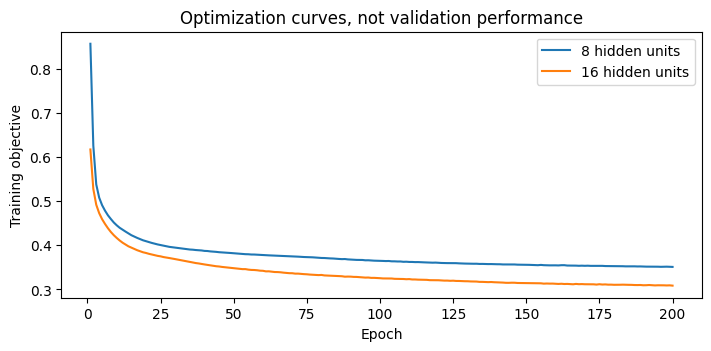

In [8]:
network_candidates = {}
network_records = []
for hidden_size in [8, 16]:
    candidate = MLPClassifier(hidden_layer_sizes=(hidden_size,), activation='relu', solver='adam',
                              alpha=0.01, batch_size=128, learning_rate_init=0.001,
                              max_iter=200, n_iter_no_change=15, early_stopping=False,
                              random_state=SEED)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        candidate.fit(X_train, y_train)
    messages = [str(warning.message) for warning in caught]
    print(f'Hidden size {hidden_size}: {candidate.n_iter_} epochs; warnings: {messages or "none"}')
    probabilities = candidate.predict_proba(X_validation)[:, 1]
    network_candidates[hidden_size] = candidate
    network_records.append({'hidden_units': hidden_size, 'epochs': candidate.n_iter_,
                            'validation_ap': average_precision_score(y_validation, probabilities),
                            'warnings': len(messages)})
network_comparison = pd.DataFrame(network_records).set_index('hidden_units')
display(network_comparison)
best_size = int(network_comparison['validation_ap'].idxmax())
network = network_candidates[best_size]
print('Selected hidden size:', best_size)
print('Weight shapes:', [weights.shape for weights in network.coefs_])
print('Bias shapes:', [bias.shape for bias in network.intercepts_])
print('Output activation:', network.out_activation_)
print('MLP parameters:', sum(weights.size for weights in network.coefs_) + sum(bias.size for bias in network.intercepts_))
hidden = np.maximum(0, X_validation[:5] @ network.coefs_[0] + network.intercepts_[0])
output_score = hidden @ network.coefs_[1] + network.intercepts_[1]
manual_network_probability = np.exp(-np.logaddexp(0, -output_score)).ravel()
np.testing.assert_allclose(manual_network_probability, network.predict_proba(X_validation[:5])[:, 1])
validation_probabilities['Neural network'] = network.predict_proba(X_validation)[:, 1]
display(pd.DataFrame({name: metrics_at_threshold(y_validation, probabilities)
                      for name, probabilities in validation_probabilities.items()}).T.round(4))
figure, axis = plt.subplots(figsize=(7, 3.4), constrained_layout=True)
for size, candidate in network_candidates.items():
    axis.plot(np.arange(1, len(candidate.loss_curve_) + 1), candidate.loss_curve_, label=f'{size} hidden units')
axis.set(xlabel='Epoch', ylabel='Training objective', title='Optimization curves, not validation performance')
axis.legend()
plt.show()

## 5. Select thresholds using validation costs

Assume a false positive costs **5 units** and a false negative costs **1 unit**. Flag an email when its probability reaches the threshold. The supplied code searches thresholds 0.05 to 0.95 in steps of 0.01, using validation data only. The no-skill baseline keeps threshold 0.5.

**Coding task:** calculate `cost` from `FALSE_POSITIVE_COST`, `FALSE_NEGATIVE_COST`, `false_positive` and `false_negative`. The search and comparison table are provided.

**Question:** Why can the highest-AP model still be a poor business policy? Why must we not choose a threshold from the test results? What if the selected value is the edge of the search grid?

<details>
<summary>Answer and self-check</summary>

**Answer:** The assumed cost is $5\,\mathrm{FP}+\mathrm{FN}$. AP summarizes ranking, while a chosen threshold determines error counts. A false positive is five times as costly as a false negative under these assumptions; actual review costs and capacity need business validation. Costs are illustrative units, not measured financial savings.

The checked seed-7 run selects logistic threshold **0.95** and MLP threshold **0.82**. These minimize validation cost only within the supplied grid. Logistic regression is at its upper edge, so this is not evidence of a global optimum. Any further search belongs to development, not test-driven tuning. Models and thresholds must be frozen before test evaluation. Repeated validation reuse can also overfit development decisions.

**Intermediate, 3 points:** weighted FP/FN calculation (1); distinguish ranking from threshold-dependent costs (1); preserve validation/test roles and recognize grid limits (1). **Common mistake:** selecting a threshold after inspecting test cost, or equating AP with financial benefit.

</details>

In [9]:
FALSE_POSITIVE_COST = 5
FALSE_NEGATIVE_COST = 1
models = {'Prior baseline': baseline, 'Logistic regression': logistic,
          'Neural network': network}
validation_probabilities = {name: model.predict_proba(X_validation)[:, 1]
                            for name, model in models.items()}
thresholds = {'Prior baseline': 0.5}
threshold_records = []
for name in ['Logistic regression', 'Neural network']:
    probabilities = validation_probabilities[name]
    candidates = []
    for threshold in np.linspace(0.05, 0.95, 91):
        true_negative, false_positive, false_negative, true_positive = confusion_matrix(
            y_validation, probabilities >= threshold, labels=[0, 1]).ravel()
        cost = FALSE_POSITIVE_COST * false_positive + FALSE_NEGATIVE_COST * false_negative
        candidates.append((cost, float(threshold)))
    best_cost, best_threshold = min(candidates)
    thresholds[name] = best_threshold
for name, probabilities in validation_probabilities.items():
    selected_threshold = thresholds[name]
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        y_validation, probabilities >= selected_threshold, labels=[0, 1]).ravel()
    threshold_records.append({'model': name, 'threshold': selected_threshold,
                              'cost_per_1000': 1000 * (FALSE_POSITIVE_COST * false_positive + FALSE_NEGATIVE_COST * false_negative) / len(y_validation),
                              **metrics_at_threshold(y_validation, probabilities, selected_threshold)})
display(pd.DataFrame(threshold_records).set_index('model').round(4))
print('Frozen architecture:', network.hidden_layer_sizes, '| thresholds:', thresholds)

,threshold,cost_per_1000,precision,recall,f1,average_precision,flagged_fraction
model,,,,,,,
Prior baseline,0.50,296.6667,0.0000,0.0000,0.0000,0.2967,0.0000
Logistic regression,0.95,295.6667,0.8542,0.0230,0.0449,0.5993,0.0080
Neural network,0.82,232.8333,0.9153,0.4006,0.5572,0.8353,0.1298


Frozen architecture: (16,) | thresholds: {'Prior baseline': 0.5, 'Logistic regression': 0.95, 'Neural network': 0.82}


## 6. Evaluate fixed choices and recommend a policy

The supplied tables and plots compare the prior baseline, logistic regression and selected MLP using their frozen validation-selected thresholds. Error inspection shows only numerical features and source-row numbers, not raw email text. The first three errors in fixed test order are illustrations, not representative error samples.

**Question:** Which policy has the lowest assumed cost per 1,000 emails? How do precision and recall qualify that recommendation? Does a cheap policy that flags nothing provide useful spam screening? Should we change a model after inspecting these test errors?

<details>
<summary>Answer and self-check</summary>

**Answer:** In the checked seed-7 run, the MLP has the lowest assumed cost: approximately **227.8 units per 1,000**, versus **296.7** for the prior baseline and **299.0** for logistic regression. Its precision is approximately **92.5%** and recall **39.2%**: most flagged emails are spam, but most spam is still missed. This supports a limited review-policy comparison under the stated costs, not automatic deletion or deployment approval.

The prior flags no emails, so it has no false positives but zero recall; low cost alone does not establish a useful screening service. A better AP does not guarantee a better threshold-dependent policy. Inspecting errors is useful for proposing future work, but do not retune on these test messages. The historical test has been inspected before: fresh, preferably time-ordered evaluation and realistic costs/capacity are needed before operational claims. Numerical results can vary with the environment.

**Intermediate, 4 points:** compare costs against both alternatives (1); qualify using precision and recall (1); explain the no-action baseline (1); keep test inspection separate from development and future confirmation (1). **Common mistake:** declaring deployment readiness from one cost table or modifying the model to fix a selected test example.

</details>

,threshold,precision,recall,f1,average_precision,flagged_fraction,false_positives,false_negatives,cost_per_1000
model,,,,,,,,,
Prior baseline,0.50,0.0000,0.0000,0.0000,0.2967,0.0000,0,1780,296.6667
Logistic regression,0.95,0.7931,0.0258,0.0501,0.5843,0.0097,12,1734,299.0000
Neural network,0.82,0.9245,0.3921,0.5507,0.8356,0.1258,57,1082,227.8333


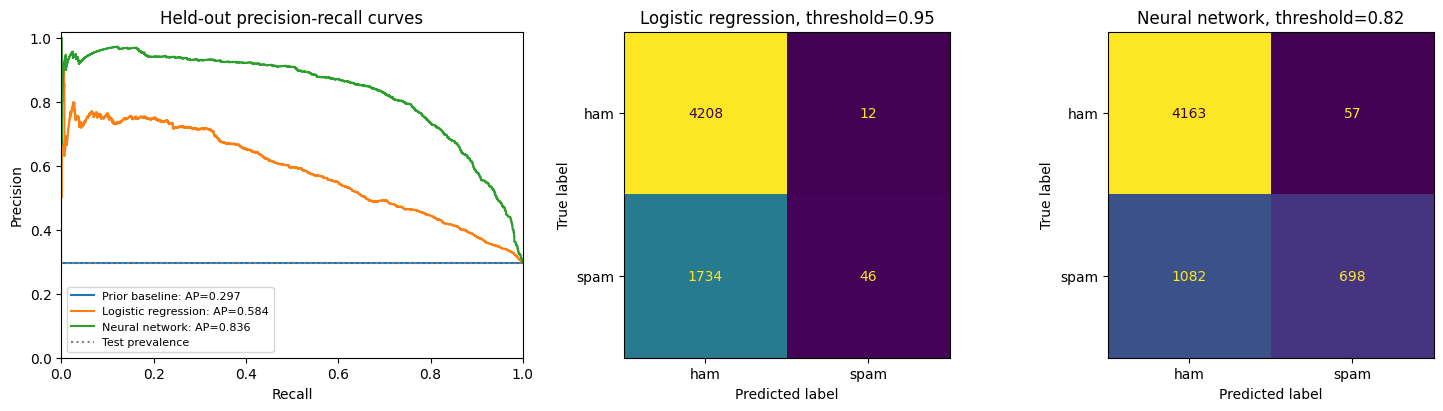

Historical test results are reused from earlier work, not fresh independent confirmation.
Do not retune on these results. They do not establish future-email performance or causal effects.


In [10]:
test_probabilities = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}
test_records = []
for name, probabilities in test_probabilities.items():
    threshold = thresholds[name]
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        y_test, probabilities >= threshold, labels=[0, 1]).ravel()
    test_records.append({'model': name, 'threshold': threshold,
                         **metrics_at_threshold(y_test, probabilities, threshold),
                         'false_positives': false_positive, 'false_negatives': false_negative,
                         'cost_per_1000': 1000 * (FALSE_POSITIVE_COST * false_positive + FALSE_NEGATIVE_COST * false_negative) / len(y_test)})
test_results = pd.DataFrame(test_records).set_index('model')
display(test_results.round(4))
figure, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for name, probabilities in test_probabilities.items():
    precision, recall, curve_thresholds = precision_recall_curve(y_test, probabilities)
    axes[0].step(recall, precision, where='post',
                 label=f'{name}: AP={average_precision_score(y_test, probabilities):.3f}')
axes[0].axhline(y_test.mean(), color='gray', linestyle=':', label='Test prevalence')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Held-out precision-recall curves', xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8)
for axis, name in zip(axes[1:], ['Logistic regression', 'Neural network']):
    ConfusionMatrixDisplay.from_predictions(y_test, test_probabilities[name] >= thresholds[name],
                                            display_labels=['ham', 'spam'], ax=axis, colorbar=False)
    axis.set_title(f'{name}, threshold={thresholds[name]:.2f}')
plt.show()
print('Historical test results are reused from earlier work, not fresh independent confirmation.')
print('Do not retune on these results. They do not establish future-email performance or causal effects.')

In [11]:
print('Inspect limited false positives and false negatives without exposing email text')
network_predictions = test_probabilities['Neural network'] >= thresholds['Neural network']
error_rows = test[['label', 'source_row']].copy()
error_rows['spam_probability'] = test_probabilities['Neural network']
error_rows['predicted_label'] = network_predictions.astype(int)
error_features = preprocessing.named_steps['features'].transform(test_messages)
for error_name, mask in [('False positives', (y_test == 0) & network_predictions),
                         ('False negatives', (y_test == 1) & ~network_predictions)]:
    positions = np.flatnonzero(mask)[:3]
    print(error_name, '- first three in fixed test order, not representative samples')
    display(error_rows.iloc[positions].join(error_features[['word_count', 'uppercase_letter_ratio',
                                                           'url_count', 'term_free_count']]))
print('Raw subject/body content is withheld rather than incompletely redacted. Source rows enable authorized local review.')

Inspect limited false positives and false negatives without exposing email text
False positives - first three in fixed test order, not representative samples


,label,source_row,spam_probability,predicted_label,word_count,uppercase_letter_ratio,url_count,term_free_count
24012,0,18333,0.838009,1,9.0,0.025641,2.0,0.0
24071,0,226634,0.994037,1,510.0,0.061622,0.0,0.0
24158,0,260709,0.962735,1,941.0,0.075532,0.0,0.0


False negatives - first three in fixed test order, not representative samples


,label,source_row,spam_probability,predicted_label,word_count,uppercase_letter_ratio,url_count,term_free_count
24006,1,89691,0.204537,0,119.0,0.046847,0.0,0.0
24008,1,166075,0.596306,0,21.0,0.000000,0.0,0.0
24014,1,45194,0.739087,0,104.0,0.055336,1.0,0.0


Raw subject/body content is withheld rather than incompletely redacted. Source rows enable authorized local review.


## Summary and further exercises

- Logistic regression uses one sigmoid output; an MLP adds hidden ReLU units while keeping the same 16 input features.
- Fit preprocessing and models only on training data. Use validation evidence to select the hidden size and cost-based thresholds.
- Read AP, precision, recall and assumed cost together. An all-ham baseline can look inexpensive without finding any spam.
- Learned coefficients and neural-network weights describe associations, not causal effects. Correlated features complicate interpretation.
- Simple counts miss meaning; subjects can be absent and parsing imperfect. Near-duplicates and related campaigns can cross random splits. Historical test reuse is not fresh confirmation of future performance.
- Protect data and model artifacts. Features and hashed identifiers are not a guarantee of anonymity. Operational use needs probability checks, review-capacity analysis, time-ordered evaluation, human oversight and monitoring.

### Optional practical exercises

Possible extensions beyond the core exercise:
1. Compare XGBoost on the same features; it is a tree model, not a neural network. Its native library and Python package are additional dependencies.
2. Save preprocessing, classifier and threshold together and check synthetic messages. Load only trusted joblib artifacts. Synthetic probes reveal possible failures, not benchmark performance.
3. Compare frozen text embeddings or an extra hidden layer. Embeddings require an additional environment, authorized private raw text and verified reference split identities. The feature-only CSV cannot reconstruct email text.
4. Compare a predeclared count transformation or TF-IDF baseline. TF-IDF requires private raw text. Change one factor at a time and plan fresh evaluation before using old test findings to guide improvements.

**Transfer question:** Suppose spam campaigns change next month. What evidence would you require before automatically deleting high-scoring messages?

<details>
<summary>Answer and self-check</summary>

**Answer:** Use new, time-ordered labelled data to evaluate fixed choices, check calibration and false positives under realistic asymmetric costs, assess review capacity, and monitor drift. Investigate failure cases with authorized access to raw messages and retain human oversight. Fluent-looking or high-confidence predictions do not justify automatic deletion; this notebook's counts and historical comparison are insufficient evidence.

**Advanced, 3 points:** fresh temporal evaluation (1); realistic decision costs/calibration and workload (1); oversight and monitoring (1). **Common mistake:** assuming a high historical AP guarantees safe automation.

</details>

## References

**Required student reading:** James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An Introduction to Statistical Learning: With Applications in Python*. Springer. Selected classification and neural-network material. https://www.statlearning.com/

**Optional reading / instructor reference:** Molnar, C. *Interpretable Machine Learning*, 2nd ed. Coefficients and interpretation limitations. https://christophm.github.io/interpretable-ml-book/

**Dataset:** NIKHIL CHAUDHARY 7108. (n.d.). *Spam email dataset (Enron, TREC and others)*. [Kaggle](https://www.kaggle.com/datasets/nikhilchaudhary7108/spam-email-datasetenron-trec-and-others). Upstream rights and labels have not been independently audited. This notebook reads [the local prepared CSV](../../../00_Data/email_spam.csv); see [the repository README](../../../README.md) for preparation and limits.

**Official technical documentation:** [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html), [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html) and [safe model persistence](https://scikit-learn.org/stable/model_persistence.html).

**Environment:** [Repository requirements](../../../requirements.txt). Installed versions are displayed above; the footer records the runtime.

### Jupyter notebook - footer info

Include this information when submitting your notebook.

In [12]:
import platform
from datetime import datetime

print(platform.platform())
print('Python:', platform.python_version())
print('Date:', datetime.now().isoformat(timespec='seconds'))

macOS-26.6.2-x86_64-i386-64bit
Python: 3.9.13
Date: 2026-10-25T19:06:50
